<a href="https://colab.research.google.com/github/chenharry66/adversial-audio-experiments/blob/main/perturbation_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Setup

In [ ]:
#install depencies
!pip install werpy scipy

In [ ]:
# import dependncies
import werpy, torch

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from scipy.io import wavfile

rate, data = wavfile.read('/content/drive/MyDrive/FOLDER/01/recording2.wav')

data.dtype

dtype('int16')

In [ ]:
clip = data[:160000]

In [ ]:
import numpy as np

clip = clip / 32768

In [ ]:
from IPython.display import Audio

audio = Audio(data = clip, rate = rate, normalize=False)
audio

##Model Definition and Establishing a Baseline

We now have our target audio. We will then initialize our frozen ASR model. Eventually after breaking whisper tiny, we can scale to more complex architectures.

In [ ]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration

processor = WhisperProcessor.from_pretrained("openai/whisper-tiny")
model = WhisperForConditionalGeneration.from_pretrained("openai/whisper-tiny")

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.75k [00:00<?, ?B/s]

In [ ]:
input_features = processor(clip, sampling_rate=rate, return_tensors="pt")["input_features"]
predicted_ids = model.generate(input_features)

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


In [ ]:
transcription = processor.batch_decode(predicted_ids, skip_special_tokens=False)

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


In [ ]:
transcription =  "".join(transcription)

In [ ]:
reference = "I must make an admission,” Ivan began. “I never could understand how it’s ‘possible to love one’s neighbors"

In [ ]:
import regex as re

def custom_normalize(text):
    clean_text = re.sub(r'[\p{P}\p{S}]', '', text)
    return werpy.normalize(clean_text)

In [ ]:
reference = custom_normalize(reference)
transcription = custom_normalize(transcription)

In [ ]:
wer = werpy.wer(reference, transcription)
print(f"Baseline Wer: {wer * 100:.2f}%")

Baseline Wer: 33.33%


Our baseline WER measurement is 33%.



## Perturbial Optimization within Whole Audio Timeframe

We can think of perturbial generation as a naive constrained optimization problem, where we are optimizing against some differentiable loss function (in this case we define that loss funciton to be CTC loss) and our constraint is that the SNR for the clip has to be under some limit. From previous experiments,**we define that SNR to be 23dB initially.** We can think of our adverserial perturbation δ as essentially an array of weights where each weight **$w_t$ represents the amplitude of the waveform at time t.** For each iteration of training, we take our initial audio waveform $x$, add $\delta$ to it, and transcribe the result using our frozen model. And then we backpropogate, moving in direction of the loss function's gradient, taking a PGD like approach where we clip back to the boundrayr whenever the SNR exceeds our limit.

In [ ]:
audio_rms = np.sqrt(np.mean(clip ** 2))

In [ ]:
audio_rms

np.float64(0.0061113801398986626)

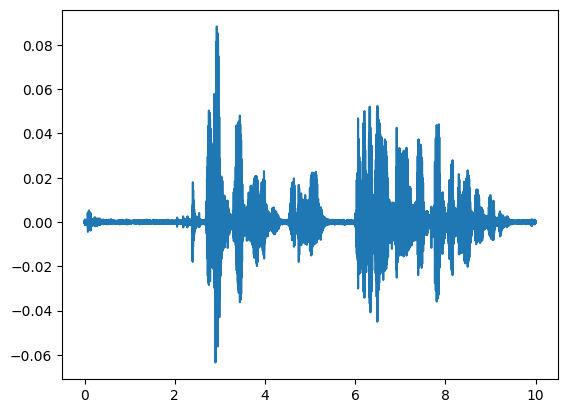

In [ ]:
import matplotlib.pyplot as plt

t = np.linspace(0, 10, int(rate * 10), endpoint=False)
plt.plot(t, clip)

In [ ]:
clip = torch.tensor(clip)
delta = torch.zeros_like(clip, requires_grad=True)

/tmp/ipykernel_1696/1991140887.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  clip = torch.tensor(clip)


In [ ]:
clip

tensor([0.0005, 0.0007, 0.0006,  ..., 0.0003, 0.0002, 0.0003],
       dtype=torch.float64)

In [ ]:
delta

tensor([0., 0., 0.,  ..., 0., 0., 0.], dtype=torch.float64, requires_grad=True)

In [ ]:
from torch.nn import CTCLoss

MAX_ITERS = 1000
ALPHA = 10e-3

model.eval()


# for i in range(MAX_ITERS):
#     # forward pass
#     perturbation = clip + delta
#     input_features = processor(perturbation.numpy(), sampling_rate = rate, return_tensors="pt")["input_feautres"]
#     predicted_ids = model.generate(input_features)

#     ctc_loss = CTCLoss

#     loss = ctc_loss(perturbation, reference, input_lengths, target_lengths)

#     loss.backward()

#     transcription = processor.batch_decode(predicted_ids, skip_special_tokens=False)
#     # get the CTC loss

WhisperForConditionalGeneration(
  (model): WhisperModel(
    (encoder): WhisperEncoder(
      (conv1): Conv1d(80, 384, kernel_size=(3,), stride=(1,), padding=(1,))
      (conv2): Conv1d(384, 384, kernel_size=(3,), stride=(2,), padding=(1,))
      (embed_positions): Embedding(1500, 384)
      (layers): ModuleList(
        (0-3): 4 x WhisperEncoderLayer(
          (self_attn): WhisperAttention(
            (k_proj): Linear(in_features=384, out_features=384, bias=False)
            (v_proj): Linear(in_features=384, out_features=384, bias=True)
            (q_proj): Linear(in_features=384, out_features=384, bias=True)
            (out_proj): Linear(in_features=384, out_features=384, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (fin

In [ ]:
perturbation = clip + delta
for p in model.parameters():
    p.requires_grad = False

# predicted_ids = model.generate(input_features)


In [ ]:
from torch import stft


def hertz_to_mel(freq: float | np.ndarray, mel_scale: str = "htk") -> float | np.ndarray:
    """
    Convert frequency from hertz to mels.

    Args:
        freq (`float` or `np.ndarray`):
            The frequency, or multiple frequencies, in hertz (Hz).
        mel_scale (`str`, *optional*, defaults to `"htk"`):
            The mel frequency scale to use, `"htk"`, `"kaldi"` or `"slaney"`.

    Returns:
        `float` or `np.ndarray`: The frequencies on the mel scale.
    """

    if mel_scale not in ["slaney", "htk", "kaldi"]:
        raise ValueError('mel_scale should be one of "htk", "slaney" or "kaldi".')

    if mel_scale == "htk":
        return 2595.0 * np.log10(1.0 + (freq / 700.0))
    elif mel_scale == "kaldi":
        return 1127.0 * np.log(1.0 + (freq / 700.0))

    min_log_hertz = 1000.0
    min_log_mel = 15.0
    logstep = 27.0 / np.log(6.4)
    mels = 3.0 * freq / 200.0

    if isinstance(freq, np.ndarray):
        log_region = freq >= min_log_hertz
        mels[log_region] = min_log_mel + np.log(freq[log_region] / min_log_hertz) * logstep
    elif freq >= min_log_hertz:
        mels = min_log_mel + np.log(freq / min_log_hertz) * logstep

    return mels


def mel_to_hertz(mels: float | np.ndarray, mel_scale: str = "htk") -> float | np.ndarray:
    """
    Convert frequency from mels to hertz.

    Args:
        mels (`float` or `np.ndarray`):
            The frequency, or multiple frequencies, in mels.
        mel_scale (`str`, *optional*, `"htk"`):
            The mel frequency scale to use, `"htk"`, `"kaldi"` or `"slaney"`.

    Returns:
        `float` or `np.ndarray`: The frequencies in hertz.
    """

    if mel_scale not in ["slaney", "htk", "kaldi"]:
        raise ValueError('mel_scale should be one of "htk", "slaney" or "kaldi".')

    if mel_scale == "htk":
        return 700.0 * (np.power(10, mels / 2595.0) - 1.0)
    elif mel_scale == "kaldi":
        return 700.0 * (np.exp(mels / 1127.0) - 1.0)

    min_log_hertz = 1000.0
    min_log_mel = 15.0
    logstep = np.log(6.4) / 27.0
    freq = 200.0 * mels / 3.0

    if isinstance(mels, np.ndarray):
        log_region = mels >= min_log_mel
        freq[log_region] = min_log_hertz * np.exp(logstep * (mels[log_region] - min_log_mel))
    elif mels >= min_log_mel:
        freq = min_log_hertz * np.exp(logstep * (mels - min_log_mel))

    return freq

  """
    Creates a triangular filter bank.

    Adapted from *torchaudio* and *librosa*.

    Args:
        fft_freqs (`np.ndarray` of shape `(num_frequency_bins,)`):
            Discrete frequencies of the FFT bins in Hz.
        filter_freqs (`np.ndarray` of shape `(num_mel_filters,)`):
            Center frequencies of the triangular filters to create, in Hz.

    Returns:
        `np.ndarray` of shape `(num_frequency_bins, num_mel_filters)`
    """
    filter_diff = np.diff(filter_freqs)
    slopes = np.expand_dims(filter_freqs, 0) - np.expand_dims(fft_freqs, 1)
    down_slopes = -slopes[:, :-2] / filter_diff[:-1]
    up_slopes = slopes[:, 2:] / filter_diff[1:]
    return np.maximum(np.zeros(1), np.minimum(down_slopes, up_slopes))

        self.mel_filters = mel_filter_bank(
            num_frequency_bins=1 + n_fft // 2,
            num_mel_filters=feature_size,
            min_frequency=0.0,
            max_frequency=8000.0,
            sampling_rate=sampling_rate,
            norm="slaney",
            mel_scale="slaney",
        )



# FUNCTION FOR CERAITNG MEL

# center points of the triangular mel filters
    mel_min = hertz_to_mel(min_frequency, mel_scale=mel_scale)
    mel_max = hertz_to_mel(max_frequency, mel_scale=mel_scale)
    mel_freqs = np.linspace(mel_min, mel_max, num_mel_filters + 2)
    filter_freqs = mel_to_hertz(mel_freqs, mel_scale=mel_scale)

    if triangularize_in_mel_space:
        # frequencies of FFT bins in Hz, but filters triangularized in mel space
        fft_bin_width = sampling_rate / ((num_frequency_bins - 1) * 2)
        fft_freqs = hertz_to_mel(fft_bin_width * np.arange(num_frequency_bins), mel_scale=mel_scale)
        filter_freqs = mel_freqs
    else:
        # frequencies of FFT bins in Hz
        fft_freqs = np.linspace(0, sampling_rate // 2, num_frequency_bins)

    mel_filters = _create_triangular_filter_bank(fft_freqs, filter_freqs)

    if norm is not None and norm == "slaney":
        # Slaney-style mel is scaled to be approx constant energy per channel
        enorm = 2.0 / (filter_freqs[2 : num_mel_filters + 2] - filter_freqs[:num_mel_filters])
        mel_filters *= np.expand_dims(enorm, 0)

    if (mel_filters.max(axis=0) == 0.0).any():
        warnings.warn(
            "At least one mel filter has all zero values. "
            f"The value for `num_mel_filters` ({num_mel_filters}) may be set too high. "
            f"Or, the value for `num_frequency_bins` ({num_frequency_bins}) may be set too low."
        )

    return mel_filters






# THE AACTUAL CODE THEN FOR GENERATING SMAP{LES}



        window = torch.hann_window(400)
        stft = torch.stft(waveform, 400, 160, window=window, return_complex=True)
        magnitudes = (stft[..., :-1].abs() ** 2).contiguous()

        mel_filters = torch.from_numpy(self.mel_filters).to(device, torch.float32)
        mel_spec = mel_filters.T @ magnitudes
        log_spec = torch.clamp(mel_spec, min=1e-10).log10()
        if waveform.dim() == 2:
            max_val = log_spec.max(dim=2, keepdim=True)[0].max(dim=1, keepdim=True)[0]
            log_spec = torch.maximum(log_spec, max_val - 8.0)
        else:
            log_spec = torch.maximum(log_spec, log_spec.max() - 8.0)
        log_spec = (log_spec + 4.0) / 4.0

inputs = processor.feature_extractor(
    perturbation,
    sampling_rate = 16000,
    return_tensors ="pt"
)['input_features']

RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.

In [ ]:
labels = processor.tokenizer(reference, return_tensors="pt", return_attention_mask=False)['input_ids']

In [ ]:
outputs = model(inputs, labels=labels, return_tensors="pt")
# doesnt output a ctc matrix outputs a p
loss = outputs.loss


In [ ]:
outputs.grad_fn

AttributeError: 'Seq2SeqLMOutput' object has no attribute 'grad_fn'

In [ ]:
loss.backward()

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

## Perturbial Optimization Within Windowed-Timeframes

## Psychoacoustic Perturbial Optimizations